# Household Rainwater Tank Sizing Under Uncertain Rainfall — Kilinochchi, Sri Lanka

**Summary:** This project uses Python simulation to study how tank size affects household rainwater availability in Kilinochchi. Rainfall is modelled using a monthly Markov chain and a shifted-gamma distribution, based on NASA POWER rainfall data from 2015–2024.

The simulation tracks daily water collection, storage, overflow, and household demand. Monte Carlo experiments are used to estimate reliability, meaning the percentage of days when the household's full water demand is met.

The notebook also includes model verification, rainfall validation, sensitivity analysis, and 95% confidence intervals.

**Contents:**
1. Title
2. Problem and research question
3. Model and assumptions
4. Implementation
5. Verification
6. Experiments and results
7. Discussion and limitations
8. References

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Problem and question

Rainfall in Kilinochchi changes throughout the year, making it difficult to choose a suitable rainwater tank size. This study uses simulation to find out how tank capacity affects the number of days a household can meet its water needs.

The main question is whether a tank can achieve 75% reliability and how roof size or daily water demand affects the result.

## 3. Model, assumptions and equations

**Rainfall occurrence — Markov chain (module topic: Markov chains, DTMC).** Let $W_t\in\{0,1\}$ indicate a wet day (rain $\ge r_0 = 1$ mm). With $m(t)$ the calendar month of day $t$:

$$\Pr(W_t=1\mid W_{t-1}=0)=p_{DW,m(t)},\qquad \Pr(W_t=1\mid W_{t-1}=1)=p_{WW,m(t)}$$

estimated by counting transitions, $\hat p_{DW,m}=N_m(D\to W)/N_m(D)$ and $\hat p_{WW,m}=N_m(W\to W)/N_m(W)$. For a chain with fixed parameters the stationary wet-day probability is

$$\pi_m=\frac{p_{DW,m}}{1-p_{WW,m}+p_{DW,m}}$$

which is used as an analytic check in Section 5 and to draw the initial state.

**Rainfall depth — input modelling and random variates (module topic: input modelling and random variate generation).** On a wet day the depth is a *shifted* gamma:

$$R_t=r_0+X_t,\qquad X_t\sim\mathrm{Gamma}(k_m,\theta_m)\ \ (\text{shape }k_m,\ \text{scale }\theta_m\ \text{in mm})$$

Method-of-moments on the excesses $x_i=r_i-r_0$: $\hat k=\bar x^2/s^2$, $\hat\theta=s^2/\bar x$. Fitting and sampling use the *same* shifted distribution, so no sampled value has to be clipped to the threshold.

**Water balance (mass conservation).** With roof area $A$ (m²), efficiency $\eta$, capacity $K$ (m³), daily demand $D$ (m³) and rain $R_t$ (mm):

$$C_t=\frac{R_t\,A\,\eta}{1000},\quad O_t=\max(0,S_{t-1}+C_t-K),\quad U_t=\min\!\big(D,\ S_{t-1}+C_t-O_t\big),\quad S_t=S_{t-1}+C_t-O_t-U_t$$

Order of events each day: collect → spill overflow → serve demand. Day $t$ is *fully supplied* if $D-U_t<10^{-10}$ m³.

**Reliability and Monte Carlo (module topic: Monte Carlo and the law of large numbers).** For simulated year $i$, $\rho_i$ is the fraction of fully supplied days in the **scored year**, which follows `WARMUP_YEARS` year(s) of warm-up so the tank does not start every January empty. With $N$ independent years,

$$\hat\rho=\frac1N\sum_{i=1}^N\rho_i,\qquad \hat\rho\pm 1.96\,\frac{s}{\sqrt N},\qquad \text{standard error}\propto N^{-1/2}$$

| Equation / algorithm | Module topic |
|---|---|
| Month-dependent wet/dry transition probabilities, stationary distribution $\pi_m$ | Markov chains (DTMC) |
| Shifted-gamma depths, moment fitting, inverse-transform / rejection variates inside NumPy | Input modelling and random variate generation |
| Replicated annual reliability, confidence intervals, $N^{-1/2}$ error scaling | Monte Carlo integration and the law of large numbers |

The tank balance is a discrete daily recursion, so no ODE solver is used and none is claimed.

## 4. Implementation
The simulation is developed in Python using NumPy, pandas, and Matplotlib. It downloads rainfall data, estimates model parameters, runs the tank simulation, and produces tables and graphs.

Fixed random seeds are used so the experiments can be repeated.
### 4.1 Setup, constants and random seed

In [4]:
%pip install -q numpy pandas matplotlib requests

In [5]:
import os, sys, time, shutil, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

T_START = time.time()

# Use one master seed so each experiment can be reproduced.
SEED = 20261119

# Simulation settings
TARGET_RELIABILITY = 0.75  # Share of days when the household's full demand is met
WET_THRESHOLD_MM   = 1.0   # Count a day as wet when rainfall reaches 1 mm
WARMUP_YEARS       = 1     # Let storage build up before scoring the year
N_REPS             = 200   # Simulate 200 years for each experiment
DAYS               = 365

# Example household values for the scenario, not measured data.
BASE = dict(roof_m2=100.0, efficiency=0.8, demand_m3_day=0.35)

# Save generated tables and figures in this folder.
OUT = 'outputs'
os.makedirs(OUT, exist_ok=True)

# Store the month number for each day in a 365-day year.
MONTHS_365 = pd.date_range('2023-01-01', '2023-12-31').month.to_numpy()

# Set consistent defaults for plots.
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

print('numpy', np.__version__, '| pandas', pd.__version__, '| seed', SEED)

numpy 2.4.6 | pandas 2.2.3 | seed 20261119


### 4.2 Daily tank water balance

`simulate_storage` implements the recursion of Section 3 in plain Python floats (fast enough for ~10⁷ day-steps) and then checks the daily conservation identity $S_{t-1}+C_t=S_t+U_t+O_t$ for **every** day with a vectorised assert.

In [6]:
def simulate_storage(rain_mm, capacity_m3, roof_m2, efficiency, demand_m3_day, initial_storage_m3=0.0):
    """Daily tank balance. Units: rain mm/day, roof m2, capacity & demand m3, storage m3.
    Order each day: collect -> spill overflow -> serve demand."""
    assert capacity_m3 >= 0 and roof_m2 >= 0 and 0 <= efficiency <= 1
    assert demand_m3_day >= 0 and 0 <= initial_storage_m3 <= capacity_m3 + 1e-12
    rain = np.asarray(rain_mm, dtype=float)
    assert np.all(rain >= 0)
    collected = rain * roof_m2 * efficiency / 1000.0                     # m3/day
    n = len(collected)
    storage = np.empty(n + 1); supplied = np.empty(n); overflow = np.empty(n); shortage = np.empty(n)
    cap, dem, s = float(capacity_m3), float(demand_m3_day), float(initial_storage_m3)
    storage[0] = s
    for t, c in enumerate(collected.tolist()):
        total = s + c
        if total > cap:
            ov, total = total - cap, cap
        else:
            ov = 0.0
        sup = dem if total >= dem else total
        s = total - sup
        overflow[t], supplied[t], shortage[t], storage[t + 1] = ov, sup, dem - sup, s
    # mass conservation, every day (vectorised)
    assert np.allclose(storage[:-1] + collected, storage[1:] + supplied + overflow, atol=1e-9)
    met = shortage < 1e-10
    return dict(storage=storage, collected=collected, supplied=supplied, overflow=overflow,
                shortage=shortage, met=met, reliability=float(met.mean()))

def scored_reliability(sim, days=DAYS):
    """Reliability over the LAST `days` days (the scored year after warm-up)."""
    return float(sim['met'][-days:].mean())

def reliability_ci(rain_years, capacity, roof, eff, dem):
    """Mean scored-year reliability over the replications, with a 95 % normal-approximation CI."""
    vals = np.array([scored_reliability(simulate_storage(r, capacity, roof, eff, dem)) for r in rain_years])
    mean = vals.mean(); half = 1.96 * vals.std(ddof=1) / np.sqrt(len(vals))
    return mean, max(0., mean - half), min(1., mean + half), vals

### 4.3 Rainfall generators (Markov chain + gamma)

In [7]:
def markov_wet_days(u, p_dw, p_ww, wet0):
    """Two-state chain driven by uniforms u. p_dw/p_ww may vary by day (list or array)."""
    n = len(u); wet = np.empty(n, dtype=bool); prev = bool(wet0)
    u, p_dw, p_ww = list(u), list(p_dw), list(p_ww)
    for i in range(n):
        prev = u[i] < (p_ww[i] if prev else p_dw[i])
        wet[i] = prev
    return wet

def generate_rain(months, rng, fits):
    """Seasonal rain (mm/day) for a sequence of calendar months, from monthly fits.
    wet-day depth = WET_THRESHOLD_MM + Gamma(shape, scale); initial state ~ stationary law of month 1."""
    months = np.asarray(months); idx = months - 1
    tab = {k: np.array([fits[m][k] for m in range(1, 13)]) for k in ('p_dw', 'p_ww', 'shape', 'scale')}
    n = len(months)
    u = rng.random(n)
    f0 = fits[int(months[0])]
    wet0 = rng.random() < f0['p_dw'] / (1.0 - f0['p_ww'] + f0['p_dw'])          # stationary start
    wet = markov_wet_days(u, tab['p_dw'][idx], tab['p_ww'][idx], wet0)
    depth = WET_THRESHOLD_MM + rng.gamma(tab['shape'][idx], tab['scale'][idx])  # shifted gamma
    return np.where(wet, depth, 0.0)

def generate_rain_stationary(days, rng, p_dw, p_ww, shape, scale_mm):
    """Month-independent illustrative model (used only for the web-demo reference result)."""
    u = rng.random(days)
    wet = markov_wet_days(u, [p_dw] * days, [p_ww] * days, False)
    return np.where(wet, rng.gamma(shape, scale_mm, size=days), 0.0)

### 4.4 Data: NASA POWER Daily Precipitation

This study uses daily rainfall data from **NASA POWER** for Kilinochchi (9.38° N, 80.40° E), covering **2015–2024**.

The dataset contains estimated rainfall values in mm/day rather than measurements from a local rain gauge. If the download fails, the notebook uses a previously saved copy. If neither is available, the simulation stops.

**Source:** [NASA POWER Daily API](https://power.larc.nasa.gov/docs/services/api/temporal/daily/)

In [8]:
NASA_URL = 'https://power.larc.nasa.gov/api/temporal/daily/point'
NASA_PARAMS = dict(parameters='PRECTOTCORR', community='AG', longitude=80.40, latitude=9.38,
                   start='20150101', end='20241231', format='JSON')
CACHE = 'kilinochchi_nasa_power_daily_2015_2024.csv'

def load_nasa_power():
    last = None
    for attempt in range(3):
        try:
            r = requests.get(NASA_URL, params=NASA_PARAMS, timeout=120)
            r.raise_for_status()
            raw = r.json()['properties']['parameter']['PRECTOTCORR']
            df = pd.DataFrame({'date': pd.to_datetime(list(raw), format='%Y%m%d'),
                               'rain_mm': list(raw.values())}).sort_values('date').reset_index(drop=True)
            df.loc[df.rain_mm < 0, 'rain_mm'] = np.nan            # NASA fill value is -999
            df.to_csv(CACHE, index=False)
            return df, f'NASA POWER API, downloaded {dt.datetime.now(dt.timezone.utc):%Y-%m-%d %H:%M} UTC\n  {r.url}'
        except Exception as e:
            last = e; time.sleep(3 * (attempt + 1))
    if os.path.exists(CACHE):
        print('WARNING: download failed; using the cached copy of the same NASA POWER file:', CACHE)
        return pd.read_csv(CACHE, parse_dates=['date']), f'cached copy {CACHE}'
    raise RuntimeError('NASA POWER download failed and no cached file exists; not substituting synthetic data.') from last

rain_df, DATA_SOURCE = load_nasa_power()
assert len(rain_df) >= 3650, 'unexpectedly short series'
assert (rain_df.date.diff().dropna().dt.days == 1).all(), 'dates are not contiguous daily'
assert rain_df.rain_mm.notna().mean() > 0.98, 'too many missing values'
print('Source:', DATA_SOURCE)
print(f'{len(rain_df)} daily rows, {rain_df.date.min():%Y-%m-%d} to {rain_df.date.max():%Y-%m-%d}; missing: {rain_df.rain_mm.isna().sum()}')
print(f'mean annual rainfall in the data: {rain_df.rain_mm.sum() / (len(rain_df) / 365.25):.0f} mm')

Source: NASA POWER API, downloaded 2026-11-24 05:24 UTC
  https://power.larc.nasa.gov/api/temporal/daily/point?parameters=PRECTOTCORR&community=AG&longitude=80.4&latitude=9.38&start=20150101&end=20241231&format=JSON
3653 daily rows, 2015-01-01 to 2024-12-31; missing: 0
mean annual rainfall in the data: 1490 mm


### 4.5 Calibration (Monthly Rainfall Model)

The `calibrate` function uses rainfall data to estimate monthly wet and dry day probabilities and gamma distribution parameters.

The same function is used for calibration, validation, and testing. Only valid consecutive days are considered, and the process stops if there is not enough data for a month.

In [9]:
def calibrate(df, min_count=10):
    d = df.sort_values('date').reset_index(drop=True).copy()
    valid = d.rain_mm.notna()
    d['wet'] = d.rain_mm >= WET_THRESHOLD_MM
    d['prev_wet'] = d.wet.shift(1, fill_value=False)
    ok = valid & valid.shift(1, fill_value=False) & ((d.date - d.date.shift(1)).dt.days == 1)
    d['month'] = d.date.dt.month
    fits = {}
    for m in range(1, 13):
        pairs = d[ok & (d.month == m)]
        dry, wet = pairs[~pairs.prev_wet], pairs[pairs.prev_wet]
        x = d.loc[valid & d.wet & (d.month == m), 'rain_mm'].to_numpy() - WET_THRESHOLD_MM   # excess over threshold
        if min(len(dry), len(wet), len(x)) < min_count:
            raise ValueError(f'Insufficient data to calibrate month {m}')
        mean, var = x.mean(), x.var(ddof=1)
        if not (mean > 0 and var > 0):
            raise ValueError(f'Cannot fit gamma in month {m}')
        fits[m] = dict(p_dw=float(dry.wet.mean()), p_ww=float(wet.wet.mean()),
                       shape=float(mean**2 / var), scale=float(var / mean))
    return fits

def fits_table(fits):
    t = pd.DataFrame.from_dict(fits, orient='index').rename_axis('month')
    t['mean_wet_depth_mm'] = WET_THRESHOLD_MM + t['shape'] * t['scale']
    t['stationary_wet_prob'] = t.p_dw / (1 - t.p_ww + t.p_dw)
    return t

# Validation fit: 2015-2022 only (2023-2024 are held out).  Production fit: all ten years.
fits_train = calibrate(rain_df[rain_df.date.dt.year <= 2022])
fits = calibrate(rain_df)
fit_df = fits_table(fits)
fit_df.to_csv(f'{OUT}/kilinochchi_rainfall_calibration.csv')
print('Production calibration (2015-2024):')
print(fit_df.round(3).to_string())
for f in (fits_train, fits):
    for m in f.values():
        assert 0 <= m['p_dw'] <= 1 and 0 <= m['p_ww'] <= 1 and m['shape'] > 0 and m['scale'] > 0

Production calibration (2015-2024):
        p_dw   p_ww  shape   scale  mean_wet_depth_mm  stationary_wet_prob
month                                                                     
1      0.105  0.744  0.409  19.813              9.100                0.291
2      0.098  0.621  0.415  17.294              8.182                0.205
3      0.103  0.618  0.769   4.822              4.708                0.213
4      0.198  0.774  0.622   5.441              4.386                0.467
5      0.203  0.830  0.201  33.230              7.680                0.544
6      0.174  0.580  0.474   3.986              2.891                0.292
7      0.139  0.734  0.293  12.550              4.683                0.344
8      0.205  0.792  0.489   7.532              4.681                0.496
9      0.248  0.781  0.515   8.318              5.283                0.531
10     0.466  0.897  0.798  10.031              9.006                0.819
11     0.391  0.929  0.885  15.572             14.788           

## 5. Verification

Several tests check whether the model works as expected. These include water-balance checks, 150 comparisons with a separate implementation, Markov chain tests, and recovery of known rainfall parameters from synthetic data.

The rainfall model is also compared with the 2023–2024 data that were excluded from the initial calibration.

In [10]:
# 5.1 exact limiting cases
dry = simulate_storage(np.zeros(10), 2.0, 100., .8, .2, initial_storage_m3=1.0)   # 1 m3 / 0.2 per day
assert np.isclose(dry['supplied'].sum(), 1.0) and np.isclose(dry['shortage'].sum(), 1.0)
assert np.isclose(dry['storage'][-1], 0.0) and dry['met'].sum() == 5               # 5 days served, 5 short
zero = simulate_storage([0., 100.], 0., 100., .8, .2)                              # zero capacity
np.testing.assert_allclose(zero['supplied'], [0, 0]); np.testing.assert_allclose(zero['overflow'], [0, 8.0])
nodem = simulate_storage([10., 10.], 2., 100., 1., 0.)                             # zero demand
np.testing.assert_allclose(nodem['storage'], [0, 1, 2]); assert nodem['reliability'] == 1.0
print('PASS 5.1: exact limiting cases (dry spell, zero capacity, zero demand)')

PASS 5.1: exact limiting cases (dry spell, zero capacity, zero demand)


In [11]:
#5.2 independent reference + bounds + monotonicity
def reference_storage(rain_mm, capacity, area, efficiency, demand, initial=0.):
    current, rec = float(initial), []
    for mm in rain_mm:
        total = current + float(mm) * area * efficiency / 1000.
        spill = max(total - capacity, 0.); avail = total - spill
        served = min(avail, demand); current = avail - served
        rec.append((current, served, demand - served, spill))
    return np.asarray(rec)

chk = np.random.default_rng(90210)
for case in range(150):
    n = int(chk.integers(1, 40))
    rain = chk.gamma(2., 12., size=n) * (chk.random(n) < .4)
    cap, area = float(chk.uniform(.1, 25.)), float(chk.uniform(20., 250.))
    eff, dem, ini = float(chk.uniform(.3, 1.)), float(chk.uniform(.05, 1.)), None
    ini = float(chk.uniform(0., cap))
    a = simulate_storage(rain, cap, area, eff, dem, ini)
    e = reference_storage(rain, cap, area, eff, dem, ini)
    np.testing.assert_allclose(np.column_stack((a['storage'][1:], a['supplied'], a['shortage'], a['overflow'])), e, atol=1e-10)
    assert a['storage'].min() >= -1e-10 and a['storage'].max() <= cap + 1e-10
    np.testing.assert_allclose(a['supplied'] + a['shortage'], dem, atol=1e-10)
print('PASS 5.2a: 150 randomised comparisons with an independent implementation + physical bounds')

for case in range(20):                                   # bigger tank never gives fewer fully-supplied days
    rain = chk.gamma(2., 15., size=400) * (chk.random(400) < .35)
    caps = [0., 1., 3., 8., 20.]
    rel = [simulate_storage(rain, c, 100., .8, .3)['reliability'] for c in caps]
    assert all(b >= a - 1e-12 for a, b in zip(rel, rel[1:])), rel
print('PASS 5.2b: reliability is non-decreasing in capacity on identical rainfall (20 random series)')

PASS 5.2a: 150 randomised comparisons with an independent implementation + physical bounds
PASS 5.2b: reliability is non-decreasing in capacity on identical rainfall (20 random series)


In [12]:
# 5.3 Markov chain vs analytic stationary distribution
vrng = np.random.default_rng(SEED + 11)
rows = []
for m in range(1, 13):
    p_dw, p_ww = fits[m]['p_dw'], fits[m]['p_ww']
    n = 200_000
    wet = markov_wet_days(vrng.random(n), [p_dw] * n, [p_ww] * n, False)
    rows.append((m, wet.mean(), p_dw / (1 - p_ww + p_dw)))
stat = pd.DataFrame(rows, columns=['month', 'simulated_wet_fraction', 'analytic_pi']).set_index('month')
stat['abs_error'] = (stat.simulated_wet_fraction - stat.analytic_pi).abs()
print(stat.round(4).to_string())
assert stat.abs_error.max() < 0.01, stat.abs_error.max()
print(f'PASS 5.3: simulated wet fraction matches pi_m in all 12 months (max abs error {stat.abs_error.max():.4f} < 0.01)')

       simulated_wet_fraction  analytic_pi  abs_error
month                                                
1                      0.2889       0.2913     0.0023
2                      0.2086       0.2049     0.0036
3                      0.2144       0.2127     0.0017
4                      0.4641       0.4670     0.0028
5                      0.5420       0.5439     0.0020
6                      0.2929       0.2925     0.0005
7                      0.3408       0.3437     0.0028
8                      0.4977       0.4957     0.0019
9                      0.5321       0.5309     0.0011
10                     0.8187       0.8186     0.0002
11                     0.8450       0.8467     0.0016
12                     0.5977       0.5960     0.0017
PASS 5.3: simulated wet fraction matches pi_m in all 12 months (max abs error 0.0036 < 0.01)


In [13]:
# 5.4 recovery of known parameters from synthetic data
syn_dates = pd.date_range('1700-01-01', '1999-12-31')                      # 300 synthetic years
syn_rain = generate_rain(syn_dates.month.to_numpy(), np.random.default_rng(SEED + 22), fits)
syn_df = pd.DataFrame({'date': syn_dates, 'rain_mm': np.round(syn_rain, 2)})   # 2-decimal precision like NASA data
recovered = calibrate(syn_df)
rec = pd.DataFrame({
    'p_dw_err':  [recovered[m]['p_dw'] - fits[m]['p_dw'] for m in range(1, 13)],
    'p_ww_err':  [recovered[m]['p_ww'] - fits[m]['p_ww'] for m in range(1, 13)],
    'shape_rel': [recovered[m]['shape'] / fits[m]['shape'] - 1 for m in range(1, 13)],
    'scale_rel': [recovered[m]['scale'] / fits[m]['scale'] - 1 for m in range(1, 13)],
    'mean_excess_rel': [recovered[m]['shape'] * recovered[m]['scale'] / (fits[m]['shape'] * fits[m]['scale']) - 1
                        for m in range(1, 13)]}, index=range(1, 13)).rename_axis('month')
print(rec.round(3).to_string())
assert rec.p_dw_err.abs().max() < 0.03 and rec.p_ww_err.abs().max() < 0.03
assert rec.mean_excess_rel.abs().max() < 0.10            # mean wet-day depth is what drives the tank
assert rec.shape_rel.abs().max() < 0.25 and rec.scale_rel.abs().max() < 0.25
print('PASS 5.4: known parameters recovered from 300 synthetic years '
      '(|dp| < 0.03, mean wet-day depth within 10 %, shape/scale within 25 %)')

       p_dw_err  p_ww_err  shape_rel  scale_rel  mean_excess_rel
month                                                           
1        -0.003    -0.000      0.048     -0.055           -0.010
2        -0.001    -0.007     -0.028      0.051            0.021
3        -0.003    -0.014      0.022     -0.084           -0.063
4        -0.011     0.008      0.068     -0.064            0.000
5         0.000    -0.001     -0.058      0.075            0.013
6         0.006    -0.002     -0.012      0.036            0.023
7        -0.004    -0.013      0.032     -0.042           -0.011
8        -0.001     0.004      0.001      0.026            0.027
9        -0.004    -0.001      0.040     -0.027            0.012
10        0.009    -0.001     -0.011      0.017            0.006
11       -0.010    -0.000      0.040     -0.033            0.006
12        0.004    -0.000     -0.003     -0.004           -0.007
PASS 5.4: known parameters recovered from 300 synthetic years (|dp| < 0.03, mean wet-day d

In [14]:
# 5.5 cross-language benchmark shared with the browser demo
bench_rain = np.array([0., 5., 0., 30., 0., 0., 12., 0.])
b = simulate_storage(bench_rain, 1.0, 100.0, 0.8, 0.2)
bench_expected = dict(storage=0.6, met=7, shortage=0.2, overflow=1.76, supplied=1.4)
bench_actual = dict(storage=float(b['storage'][-1]), met=int(b['met'].sum()), shortage=float(b['shortage'].sum()),
                    overflow=float(b['overflow'].sum()), supplied=float(b['supplied'].sum()))
for k, v in bench_expected.items():
    assert np.isclose(bench_actual[k], v, atol=1e-10), (k, bench_actual[k], v)
print('PASS 5.5: deterministic benchmark identical to the constants hard-coded in the web demo:', bench_actual)

PASS 5.5: deterministic benchmark identical to the constants hard-coded in the web demo: {'storage': 0.6000000000000001, 'met': 7, 'shortage': 0.2, 'overflow': 1.76, 'supplied': 1.4000000000000001}


## 6. Experiments and Results

The experiments use repeated rainfall simulations to estimate tank reliability. The same rainfall data is used when comparing different tank sizes, roof areas, water demands, and collection efficiencies to keep the comparisons fair.

Each result includes a 95% confidence interval to show the uncertainty from the simulations.

### 6.1 Rainfall Model Validation

The rainfall model is trained using data from **2015–2022** and tested against **2023–2024** rainfall data.

This helps check whether the model produces realistic rainfall patterns. However, two years of testing are not enough to fully confirm its accuracy.

                  metric  obs_2023  obs_2024  sim_mean  sim_2.5%  sim_97.5%  both_inside_95%
Rain on wet days (mm/yr)    1786.7    1287.3    1384.8    1036.7     1797.6             True
       Wet days per year     187.0     160.0     170.3     135.5      206.5             True
Longest dry spell (days)      18.0      47.0      27.0      15.0       47.5             True

Rain falling on days < 1 mm (ignored by the model): 3.7% of all observed rainfall
PASS: model reproduces the training-period wet-day rainfall total within 15 %


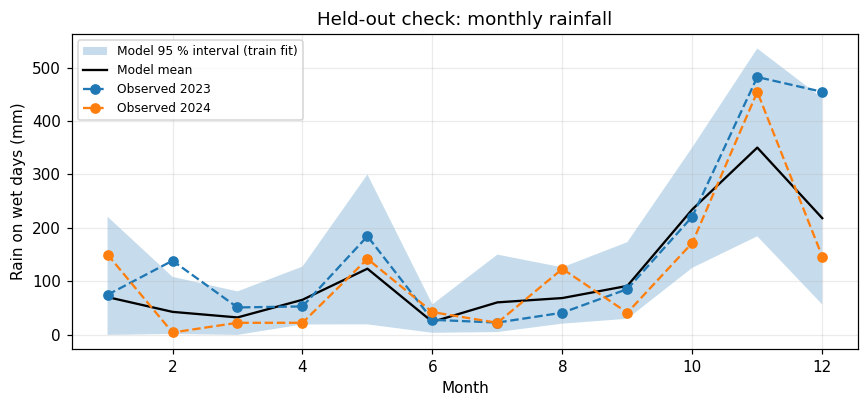

In [15]:
def longest_run(flags):
    best = cur = 0
    for f in flags:
        cur = cur + 1 if f else 0; best = max(best, cur)
    return best

def year_stats(months, rain):
    wet = rain >= WET_THRESHOLD_MM
    return dict(annual_mm=rain.sum(), wet_days=int(wet.sum()), wet_day_mm=rain[wet].sum(),
                longest_dry_spell=longest_run(~wet), monthly=np.array([rain[months == m].sum() for m in range(1, 13)]))

# simulated years from the TRAIN-only fit
sim_rng = np.random.default_rng(SEED + 300)
sim_years = [generate_rain(MONTHS_365, sim_rng, fits_train) for _ in range(500)]
sim_stats = [year_stats(MONTHS_365, r) for r in sim_years]

# held-out NASA POWER gridded estimates, 365-day years (drop Feb 29)
obs = {}
for y in (2023, 2024):
    d = rain_df[(rain_df.date.dt.year == y) & ~((rain_df.date.dt.month == 2) & (rain_df.date.dt.day == 29))]
    n_missing = int(d.rain_mm.isna().sum())
    assert len(d) == 365 and n_missing <= 5, (y, len(d), n_missing)
    if n_missing: print(f'note: {n_missing} missing day(s) in {y} treated as dry')
    obs[y] = year_stats(d.date.dt.month.to_numpy(), d.rain_mm.fillna(0).to_numpy())

drizzle = rain_df.rain_mm[(rain_df.rain_mm > 0) & (rain_df.rain_mm < WET_THRESHOLD_MM)].sum() / rain_df.rain_mm.sum()
rows = []
for key, label in [('wet_day_mm', 'Rain on wet days (mm/yr)'), ('wet_days', 'Wet days per year'),
                   ('longest_dry_spell', 'Longest dry spell (days)')]:
    s = np.array([x[key] for x in sim_stats], float)
    lo, hi = np.quantile(s, [.025, .975])
    rows.append((label, obs[2023][key], obs[2024][key], s.mean(), lo, hi,
                 all(lo <= obs[y][key] <= hi for y in obs)))
val = pd.DataFrame(rows, columns=['metric', 'obs_2023', 'obs_2024', 'sim_mean', 'sim_2.5%', 'sim_97.5%', 'both_inside_95%'])
print(val.round(1).to_string(index=False))
print(f'\nRain falling on days < {WET_THRESHOLD_MM:g} mm (ignored by the model): {drizzle:.1%} of all observed rainfall')
val.to_csv(f'{OUT}/rainfall_validation_heldout.csv', index=False)

# in-sample consistency (should hold because the fit uses these years): wet-day rain, 2015-2022 vs model
tr = rain_df[(rain_df.date.dt.year <= 2022) & ~((rain_df.date.dt.month == 2) & (rain_df.date.dt.day == 29))]
train_wet_mm = tr.rain_mm.where(tr.rain_mm >= WET_THRESHOLD_MM, 0).sum() / 8
assert abs(np.mean([x['wet_day_mm'] for x in sim_stats]) / train_wet_mm - 1) < 0.15, 'model does not reproduce training rainfall'
print('PASS: model reproduces the training-period wet-day rainfall total within 15 %')

fig, ax = plt.subplots(figsize=(8, 3.8))
mon = np.array([x['monthly'] for x in sim_stats]); xs = np.arange(1, 13)
ax.fill_between(xs, *np.quantile(mon, [.025, .975], axis=0), alpha=.25, label='Model 95 % interval (train fit)')
ax.plot(xs, mon.mean(0), 'k-', label='Model mean')
for y, st in obs.items(): ax.plot(xs, st['monthly'], 'o--', label=f'Observed {y}')
ax.set(xlabel='Month', ylabel='Rain on wet days (mm)', title='Held-out check: monthly rainfall'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_heldout_monthly.png'); plt.show()

### 6.2 Reliability against tank capacity (calibrated rainfall)

Each replication is a `WARMUP_YEARS`+1-year continuous rainfall series from the production fit; only the final year is scored.

Mean modelled annual rain on wet days: 1410 mm
Roof supply 113 m3/yr vs household demand 128 m3/yr  ->  supply/demand = 0.88
no tested capacity (1-30 m3) reaches 75% with the baseline household
 capacity_m3  mean  ci_lower  ci_upper
         1.0 0.364     0.358     0.370
         2.0 0.451     0.443     0.458
         5.0 0.532     0.523     0.541
        10.0 0.589     0.579     0.599
        15.0 0.634     0.624     0.645
        20.0 0.677     0.666     0.688
        30.0 0.758     0.746     0.769


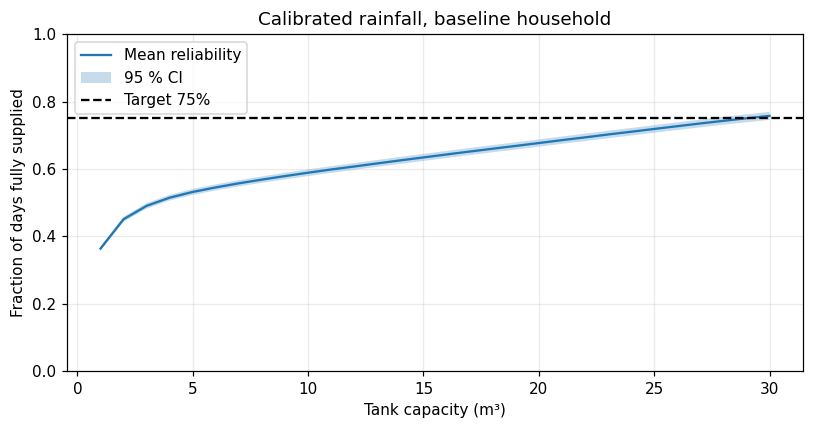

In [16]:
RAIN_YEARS = [generate_rain(np.tile(MONTHS_365, 1 + WARMUP_YEARS), np.random.default_rng(SEED + 1000 + i), fits)
              for i in range(N_REPS)]

# supply-vs-demand diagnostic: can the roof deliver enough water at all?
scored_rain = np.array([r[-DAYS:].sum() for r in RAIN_YEARS])
supply = scored_rain.mean() * BASE['roof_m2'] * BASE['efficiency'] / 1000
demand_year = BASE['demand_m3_day'] * DAYS
print(f'Mean modelled annual rain on wet days: {scored_rain.mean():.0f} mm')
print(f'Roof supply {supply:.0f} m3/yr vs household demand {demand_year:.0f} m3/yr  ->  supply/demand = {supply/demand_year:.2f}')

caps = np.arange(1., 31., 1.)
cap_rows = []
for c in caps:
    m, lo, hi, _ = reliability_ci(RAIN_YEARS, c, **{'roof': BASE['roof_m2'], 'eff': BASE['efficiency'], 'dem': BASE['demand_m3_day']})
    cap_rows.append((c, m, lo, hi))
cap_table = pd.DataFrame(cap_rows, columns=['capacity_m3', 'mean', 'ci_lower', 'ci_upper'])
cap_table.to_csv(f'{OUT}/calibrated_capacity_results.csv', index=False)
hit = cap_table[cap_table.ci_lower >= TARGET_RELIABILITY]
CAP_RESULT = (f'smallest tested capacity with lower 95 % CI >= {TARGET_RELIABILITY:.0%}: {hit.iloc[0].capacity_m3:.0f} m3'
              if len(hit) else f'no tested capacity (1-30 m3) reaches {TARGET_RELIABILITY:.0%} with the baseline household')
print(CAP_RESULT)
print(cap_table.iloc[[0, 1, 4, 9, 14, 19, 29]].round(3).to_string(index=False))

plt.figure(figsize=(7.5, 4))
plt.plot(cap_table.capacity_m3, cap_table['mean'], label='Mean reliability')
plt.fill_between(cap_table.capacity_m3.to_numpy(), cap_table.ci_lower.to_numpy(), cap_table.ci_upper.to_numpy(), alpha=.25, label='95 % CI')
plt.axhline(TARGET_RELIABILITY, ls='--', c='k', label=f'Target {TARGET_RELIABILITY:.0%}')
plt.xlabel('Tank capacity (m³)'); plt.ylabel('Fraction of days fully supplied'); plt.ylim(0, 1)
plt.title('Calibrated rainfall, baseline household'); plt.legend(); plt.tight_layout()
plt.savefig(f'{OUT}/fig_capacity_calibrated.png'); plt.show()

### 6.3 Monte Carlo error scaling

The law of large numbers predicts that the standard error of $\hat\rho$ falls as $N^{-1/2}$. We simulate `M` independent years for the baseline household with a 12 m³ tank, split them into disjoint batches of size $N$, and measure the empirical standard deviation of the batch means on a log–log plot. The fitted slope should be close to −0.5.

fitted log-log slope = -0.547  (theory: -0.5);  sigma of one year = 0.0763
PASS: Monte Carlo standard error scales as N^(-1/2)


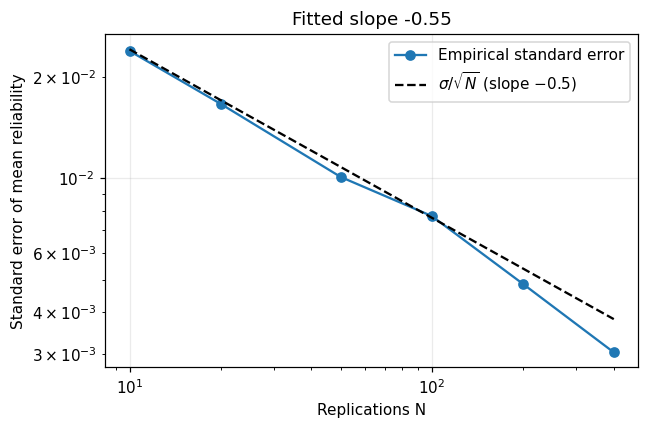

In [17]:
M = 8000; CONV_CAP = 12.0
conv = np.empty(M)
for i in range(M):
    r = generate_rain(np.tile(MONTHS_365, 1 + WARMUP_YEARS), np.random.default_rng(SEED + 50000 + i), fits)
    conv[i] = scored_reliability(simulate_storage(r, CONV_CAP, BASE['roof_m2'], BASE['efficiency'], BASE['demand_m3_day']))
Ns = np.array([10, 20, 50, 100, 200, 400])
se = np.array([conv[:(M // n) * n].reshape(-1, n).mean(axis=1).std(ddof=1) for n in Ns])
slope, intercept = np.polyfit(np.log(Ns), np.log(se), 1)
pd.DataFrame({'N': Ns, 'empirical_SE': se, 'sigma_over_sqrtN': conv.std(ddof=1) / np.sqrt(Ns)}).to_csv(f'{OUT}/mc_error_scaling.csv', index=False)
print(f'fitted log-log slope = {slope:.3f}  (theory: -0.5);  sigma of one year = {conv.std(ddof=1):.4f}')
assert -0.62 < slope < -0.38, slope
print('PASS: Monte Carlo standard error scales as N^(-1/2)')
plt.figure(figsize=(6, 4))
plt.loglog(Ns, se, 'o-', label='Empirical standard error')
plt.loglog(Ns, conv.std(ddof=1) / np.sqrt(Ns), 'k--', label=r'$\sigma/\sqrt{N}$ (slope −0.5)')
plt.xlabel('Replications N'); plt.ylabel('Standard error of mean reliability')
plt.title(f'Fitted slope {slope:.2f}'); plt.legend(); plt.tight_layout()
plt.savefig(f'{OUT}/fig_mc_error_scaling.png'); plt.show()

### 6.4 One-at-a-time sensitivity (12 m³ tank, calibrated rainfall)

        scenario  mean_reliability  ci_lower  ci_upper
        Baseline             0.607     0.597     0.618
 Roof area 60 m²             0.426     0.418     0.434
 Roof area 80 m²             0.530     0.521     0.538
Roof area 120 m²             0.677     0.665     0.688
Roof area 140 m²             0.735     0.723     0.746
Demand 200 L/day             0.899     0.888     0.910
Demand 275 L/day             0.731     0.719     0.744
Demand 425 L/day             0.522     0.513     0.531
Demand 500 L/day             0.455     0.447     0.463
  Efficiency 50%             0.442     0.434     0.450
  Efficiency 65%             0.535     0.526     0.544
  Efficiency 90%             0.652     0.641     0.663
  Efficiency 95%             0.673     0.661     0.684
PASS: sensitivities have the physically expected direction

Reliability swing across the tested range (percentage points):
group
demand        44.4
roof          30.8
efficiency    23.1


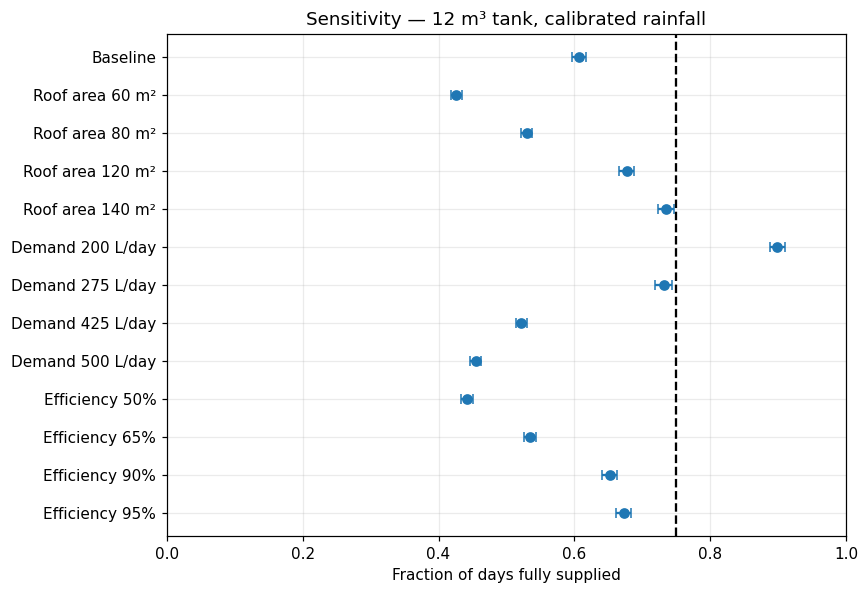

In [18]:
SENS_CAP = 12.0
scen = [('Baseline', BASE['roof_m2'], BASE['efficiency'], BASE['demand_m3_day'], 'baseline')]
scen += [(f'Roof area {a:.0f} m²', a, BASE['efficiency'], BASE['demand_m3_day'], 'roof') for a in (60., 80., 120., 140.)]
scen += [(f'Demand {d*1000:.0f} L/day', BASE['roof_m2'], BASE['efficiency'], d, 'demand') for d in (.2, .275, .425, .5)]
scen += [(f'Efficiency {e:.0%}', BASE['roof_m2'], e, BASE['demand_m3_day'], 'efficiency') for e in (.5, .65, .9, .95)]
rows = []
for name, a, e, d, grp in scen:
    m, lo, hi, _ = reliability_ci(RAIN_YEARS, SENS_CAP, a, e, d)
    rows.append(dict(scenario=name, group=grp, roof_m2=a, efficiency=e, demand_m3_day=d, mean_reliability=m, ci_lower=lo, ci_upper=hi, n=N_REPS))
sens = pd.DataFrame(rows); sens.to_csv(f'{OUT}/sensitivity_calibrated.csv', index=False)
print(sens[['scenario', 'mean_reliability', 'ci_lower', 'ci_upper']].round(3).to_string(index=False))

def sc(name): return float(sens.loc[sens.scenario == name, 'mean_reliability'].iloc[0])
assert sc('Roof area 140 m²') > sc('Roof area 60 m²') and sc('Efficiency 95%') > sc('Efficiency 50%') and sc('Demand 200 L/day') > sc('Demand 500 L/day')
print('PASS: sensitivities have the physically expected direction')

swing = sens[sens.group != 'baseline'].groupby('group').mean_reliability.agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
print('\nReliability swing across the tested range (percentage points):'); print((100 * swing).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 5.5)); y = np.arange(len(sens))
ax.errorbar(sens.mean_reliability, y, xerr=[sens.mean_reliability - sens.ci_lower, sens.ci_upper - sens.mean_reliability], fmt='o', capsize=3)
ax.set_yticks(y, sens.scenario); ax.invert_yaxis(); ax.axvline(TARGET_RELIABILITY, ls='--', c='k')
ax.set(xlabel='Fraction of days fully supplied', xlim=(0, 1), title=f'Sensitivity — {SENS_CAP:g} m³ tank, calibrated rainfall')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_sensitivity_calibrated.png'); plt.show()

### 6.5 Combined scenarios: which roof / demand / tank combinations reach the target?

If tank size alone cannot reach the target (Section 6.2), the practical question is what *combination* does. For each roof-area and demand pair we scan tank capacities and report the smallest tested capacity whose lower 95 % confidence bound reaches the target.

In [ ]:
roofs, demands = (100., 140., 180.), (0.20, 0.275, 0.35)
caps_grid = np.array([2., 4., 6., 8., 10., 12., 15., 20., 25., 30.])
rows = []
for a in roofs:
    for d in demands:
        for c in caps_grid:
            m, lo, hi, _ = reliability_ci(RAIN_YEARS, c, a, BASE['efficiency'], d)
            rows.append(dict(roof_m2=a, demand_L_day=d * 1000, capacity_m3=c, mean=m, ci_lower=lo, ci_upper=hi))
grid = pd.DataFrame(rows); grid.to_csv(f'{OUT}/combined_scenarios.csv', index=False)

best = np.full((len(roofs), len(demands)), np.nan)
peak = np.zeros_like(best)
for i, a in enumerate(roofs):
    for j, d in enumerate(demands):
        g = grid[(grid.roof_m2 == a) & (grid.demand_L_day == d * 1000)]
        ok = g[g.ci_lower >= TARGET_RELIABILITY]
        best[i, j] = ok.capacity_m3.min() if len(ok) else np.nan
        peak[i, j] = g['mean'].max()
summary = pd.DataFrame(best, index=[f'{a:.0f} m² roof' for a in roofs], columns=[f'{d*1000:.0f} L/day' for d in demands])
print(f'Smallest tested capacity (m³) meeting {TARGET_RELIABILITY:.0%} (NaN = not reached up to 30 m³):')
print(summary.to_string())
print('\nBest mean reliability reached by any tested tank:')
print(pd.DataFrame(peak, index=summary.index, columns=summary.columns).round(3).to_string())

fig, ax = plt.subplots(figsize=(5.8, 3.8))
im = ax.imshow(np.where(np.isnan(best), 35, best), cmap='viridis_r', vmin=0, vmax=35)
ax.set_xticks(range(len(demands)), summary.columns); ax.set_yticks(range(len(roofs)), summary.index)
for i in range(len(roofs)):
    for j in range(len(demands)):
        ax.text(j, i, 'not reached' if np.isnan(best[i, j]) else f'{best[i, j]:.0f} m³', ha='center', va='center', color='w', fontsize=9)
ax.set_title('Smallest tank meeting the target'); ax.grid(False); plt.tight_layout()
plt.savefig(f'{OUT}/fig_combined_scenarios.png'); plt.show()

### 6.6 Browser Demo Comparison

The browser demo uses a simplified rainfall model and runs one simulated year at a time.

The Python notebook calculates a reference average using 200 simulated years. This result is included for comparison, but the browser demo does not currently run the same 200-year experiment.

Instead, the browser's **Run reference check** button tests the daily water-balance calculations using the same eight-day rainfall sequence as Python. All five results matched, confirming that both implementations produce the same water-balance results for this test.

In [ ]:
DEMO = dict(capacity=5.0, roof=100.0, eff=0.8, dem=0.35, p_dw=0.12, p_ww=0.55, shape=2.0, scale=9.0)
vals = np.array([simulate_storage(generate_rain_stationary(DAYS, np.random.default_rng(SEED + 90000 + i), DEMO['p_dw'], DEMO['p_ww'], DEMO['shape'], DEMO['scale']),
                                  DEMO['capacity'], DEMO['roof'], DEMO['eff'], DEMO['dem'])['reliability'] for i in range(N_REPS)])
demo_mean, demo_half = vals.mean(), 1.96 * vals.std(ddof=1) / np.sqrt(N_REPS)
tol = 2 * demo_half + 0.01
pd.DataFrame([dict(**DEMO, years=N_REPS, seed_base=SEED + 90000, mean_reliability=demo_mean, ci_half_width=demo_half, demo_tolerance=tol)]).to_csv(f'{OUT}/web_demo_reference_result.csv', index=False)
print(f'Web-demo reference (empty tank at day 0, 365 days, {N_REPS} years): reliability = {demo_mean:.4f} ± {demo_half:.4f}')
print(f'The browser demo should report a value within ±{tol:.3f} of {demo_mean:.3f}.')

### 6.7 Key results (printed from the computed objects above)

In [ ]:
print('KEY RESULTS')
print(f'* Data: NASA POWER PRECTOTCORR, 9.38N 80.40E, 2015-2024 ({len(rain_df)} days); gridded estimate, not a rain-gauge record.')
print(f'* Baseline household: roof {BASE["roof_m2"]:.0f} m², efficiency {BASE["efficiency"]:.0%}, demand {BASE["demand_m3_day"]*1000:.0f} L/day; supply/demand = {supply/demand_year:.2f}.')
print(f'* Capacity sweep: {CAP_RESULT}.')
b12 = cap_table.loc[cap_table.capacity_m3 == 12.].iloc[0]
print(f'* 12 m³ tank: reliability {b12["mean"]:.1%} (95 % CI {b12.ci_lower:.1%}-{b12.ci_upper:.1%}).')
print(f'* Largest single lever (one-at-a-time swing): {swing.index[0]} ({100*swing.iloc[0]:.1f} percentage points).')
print(f'* Monte Carlo standard error scales as N^{slope:.2f} (theory -0.50).')
print(f'* Combined scenarios reaching the target within 30 m³: {int((~np.isnan(best)).sum())} of {best.size}.')

## 7. Discussion and Limitations

### Discussion

The results show that increasing tank size improves rainwater availability, but a larger tank alone may not be enough to meet the 75% reliability target.

For the baseline household, a 12 m³ tank achieved about **60.7% reliability**. The results also show that reducing daily water demand or increasing roof area can improve reliability.

### Limitations

- **Rainfall data:** NASA POWER provides estimated rainfall, which may differ from actual rainfall at a household.
- **Data period:** Only 10 years of rainfall data were used, so long-term changes may not be fully represented.
- **Model assumptions:** Roof size, collection efficiency, and daily water demand are assumed values.
- **Simplifications:** Rainfall below 1 mm is ignored. Evaporation, water quality, tank costs, and changes in daily demand are not included.
- **Uncertainty:** The confidence intervals show simulation uncertainty but do not include uncertainty in the fitted rainfall parameters.
- **Validation:** Only two years were used for testing, so further validation is needed.

Overall, the simulation helps compare different tank sizes and household conditions, but real-world measurements would be needed before making a final installation decision.

## 8. References

[1] NASA Langley Research Center, “NASA POWER Project — Daily API Documentation.” [Online]. Available: https://power.larc.nasa.gov/docs/services/api/temporal/daily/. [Accessed: Nov. 21, 2026].

[2] C. W. Richardson, “Stochastic simulation of daily precipitation, temperature, and solar radiation,” Water Resources Research, vol. 17, no. 1, pp. 182–190, 1981, doi: 10.1029/WR017i001p00182.

[3] D. S. Wilks, “Multisite generalization of a daily stochastic precipitation generation model,” Journal of Hydrology, vol. 210, no. 1–4, pp. 178–191, 1998, doi: 10.1016/S0022-1694(98)00186-3.

[4] A. M. Law, Simulation Modeling and Analysis, 5th ed. New York, NY, USA: McGraw-Hill Education, 2015.


In [ ]:
# Package the generated tables and figures
# To fetch them in Colab, uncomment the next two lines.
# from google.colab import files
# files.download(shutil.make_archive('outputs', 'zip', OUT))
shutil.make_archive('outputs', 'zip', OUT)
print('Files in', OUT + '/:', sorted(os.listdir(OUT)))
print(f'Total runtime: {(time.time() - T_START) / 60:.1f} min')